In [13]:
import pandas as pd

assay = pd.read_csv("../The_Cell_Count_Files/detailed_assaytypedata_hofmarcher.csv")
assay = assay[['Assay', 'Assay_Type', 'Assay_Description', 'Target_Type', 'Target_Name', 'Organism']].drop_duplicates().reset_index(drop=True)


In [20]:
assay.to_csv("data/Assay_description_figures.csv", index=False)

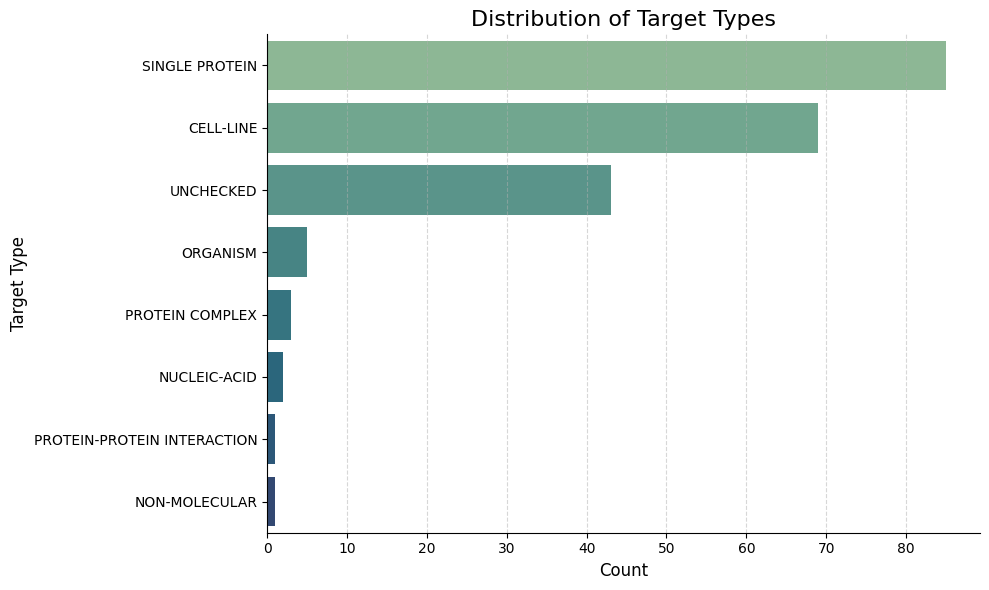

In [21]:
# Recalculate target type counts
target_type_counts = assay['Target_Type'].value_counts(dropna=False)

# Create improved plot for Target Type Distribution
plt.figure(figsize=(10, 6))
ax = sns.countplot(
    data=assay,
    y='Target_Type',
    order=target_type_counts.index,
    palette='crest'
)

# Remove top/right spines for a cleaner look
sns.despine(top=True, right=True)

# Add subtle x-axis gridlines
ax.grid(axis='x', linestyle='--', alpha=0.5)

# Titles and labels
ax.set_title('Distribution of Target Types', fontsize=16)
ax.set_xlabel('Count', fontsize=12)
ax.set_ylabel('Target Type', fontsize=12)

# Tidy layout
plt.tight_layout()
plt.show()



Top 20 Targets:
 Unchecked                                                                                   43
Plasmodium falciparum                                                                        5
Nuclear receptor ROR-gamma                                                                   4
Survival motor neuron protein                                                                3
Tyrosyl-DNA phosphodiesterase 1                                                              3
HEK293                                                                                       3
Prelamin-A/C                                                                                 3
Guanine nucleotide-binding protein G(s), subunit alpha                                       2
Thioredoxin reductase 1, cytoplasmic                                                         2
Chromobox protein homolog 1                                                                  2
Ataxin-2                        

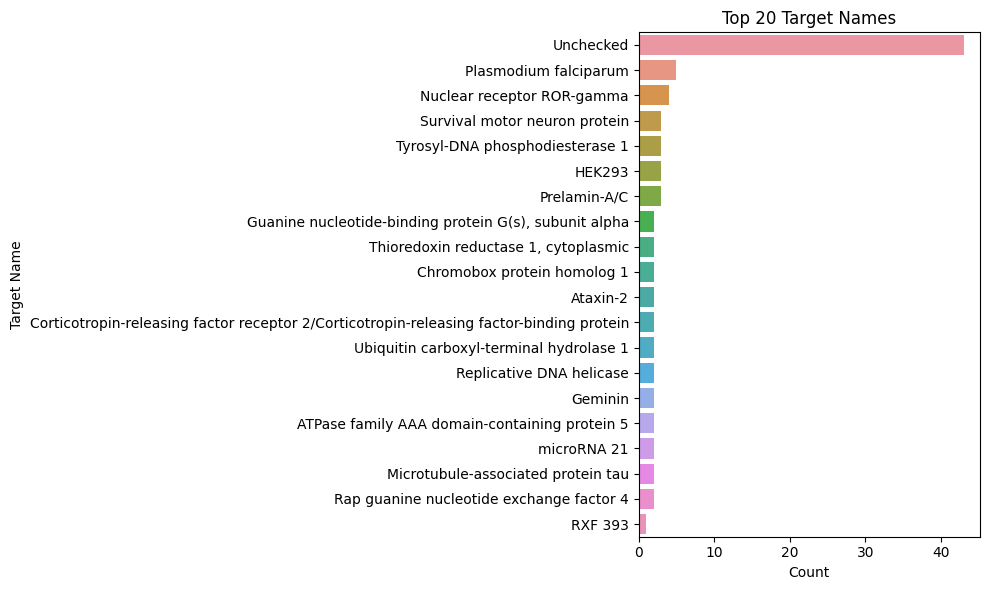

In [17]:
# Top 20 target names
top_targets = assay['Target_Name'].value_counts().head(20)
print("\nTop 20 Targets:\n", top_targets)

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(x=top_targets.values, y=top_targets.index)
plt.title('Top 20 Target Names')
plt.xlabel('Count')
plt.ylabel('Target Name')
plt.tight_layout()
plt.show()



Target Types by Organism:
 Organism                     Bacillus subtilis  \
Target_Type                                      
CELL-LINE                                    0   
NUCLEIC-ACID                                 0   
ORGANISM                                     0   
PROTEIN COMPLEX                              0   
PROTEIN-PROTEIN INTERACTION                  0   
SINGLE PROTEIN                               1   

Organism                     Bacillus subtilis (strain 168)  \
Target_Type                                                   
CELL-LINE                                                 0   
NUCLEIC-ACID                                              0   
ORGANISM                                                  0   
PROTEIN COMPLEX                                           0   
PROTEIN-PROTEIN INTERACTION                               0   
SINGLE PROTEIN                                            1   

Organism                     Candida albicans (strain WO-1) (Yeast

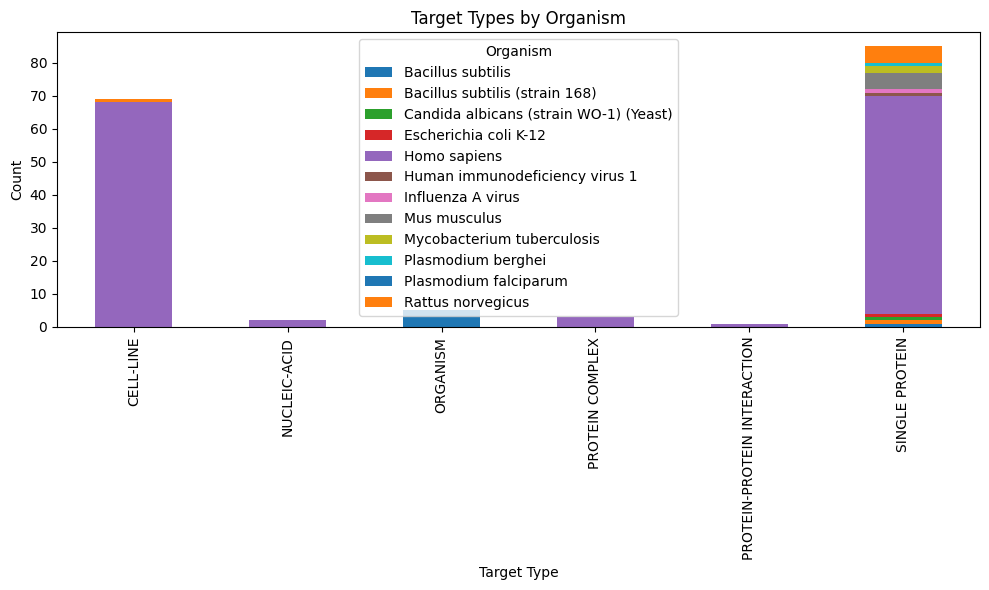

In [18]:
# Crosstab of Target_Type vs Organism
target_by_organism = pd.crosstab(assay['Target_Type'], assay['Organism'])
print("\nTarget Types by Organism:\n", target_by_organism)

# Stacked bar plot
target_by_organism.plot(kind='bar', stacked=True, figsize=(10, 6))
plt.title('Target Types by Organism')
plt.xlabel('Target Type')
plt.ylabel('Count')
plt.tight_layout()
plt.show()


In [19]:
missing_targets = assay[['Target_Type', 'Target_Name', 'Organism']].isnull().sum()
print("\nMissing Target-related Metadata:\n", missing_targets)



Missing Target-related Metadata:
 Target_Type     0
Target_Name     0
Organism       44
dtype: int64
